# **Rule-Based FX Trading Strategy Backtest in Python**

## Project overview

This notebook implements and evaluates a **rule-based trading strategy on EUR/USD** using daily data downloaded with `yfinance`.

The strategy combines three elements:

1. **Support and resistance detection**
2. **Candlestick reversal patterns**
3. **A backtesting framework with transaction costs and risk controls**

The goal is not to build a production-ready trading system, but to demonstrate a rigorous and transparent workflow for:

- downloading and cleaning market data,
- constructing trading signals without look-ahead bias,
- defining entry and exit rules,
- backtesting a strategy,
- evaluating performance with standard risk and return metrics.

## Strategy idea

The strategy looks for reversal patterns that occur close to recently confirmed support or resistance levels:

- a **bullish reversal pattern near support** generates a **long signal**
- a **bearish reversal pattern near resistance** generates a **short signal**

Trades are managed with fixed **stop loss** and **take profit** levels.

In [1]:
# Libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from backtesting import Backtest, Strategy

plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", 50)

Loading BokehJS ...

## 1. Download market data

We use daily EUR/USD data from Yahoo Finance through `yfinance`.

Ticker:
- `EURUSD=X`

In [2]:
ticker = "EURUSD=X"
start_date = "2010-01-01"
end_date = "2025-12-31"

raw = yf.download(
    ticker,
    start=start_date,
    end=end_date,
    interval="1d",
    auto_adjust=False,
    progress=False,
    group_by="column"
)


raw.columns = raw.columns.get_level_values(0)
df = raw.copy()
df.head(5)

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2010-01-01,1.438994,1.438994,1.440196,1.432706,1.432706,0
2010-01-04,1.442398,1.442398,1.445191,1.426208,1.431004,0
2010-01-05,1.436596,1.436596,1.448310,1.435194,1.442710,0
2010-01-06,1.440403,1.440403,1.443460,1.429123,1.436596,0
2010-01-07,1.431803,1.431803,1.444481,1.430206,1.440300,0


In [3]:
# Keep only the columns needed for backtesting.py
required_cols = ["Open", "High", "Low", "Close"]
missing_cols = [col for col in required_cols if col not in df.columns]

df = df[required_cols + [col for col in ["Volume"] if col in df.columns]].copy()

# Ensure DatetimeIndex and sort
df.index = pd.to_datetime(df.index)
df = df.sort_index()

# Drop rows with missing OHLC values
df = df.dropna(subset=["Open", "High", "Low", "Close"]).copy()

# Remove duplicated timestamps if any
df = df[~df.index.duplicated(keep="first")].copy()

print(df.shape)
df.head()

(4164, 5)


Price,Open,High,Low,Close,Volume
Date,,,,,
2010-01-01,1.432706,1.440196,1.432706,1.438994,0
2010-01-04,1.431004,1.445191,1.426208,1.442398,0
2010-01-05,1.442710,1.448310,1.435194,1.436596,0
2010-01-06,1.436596,1.443460,1.429123,1.440403,0
2010-01-07,1.440300,1.444481,1.430206,1.431803,0


## 2. Exploratory view of the dataset

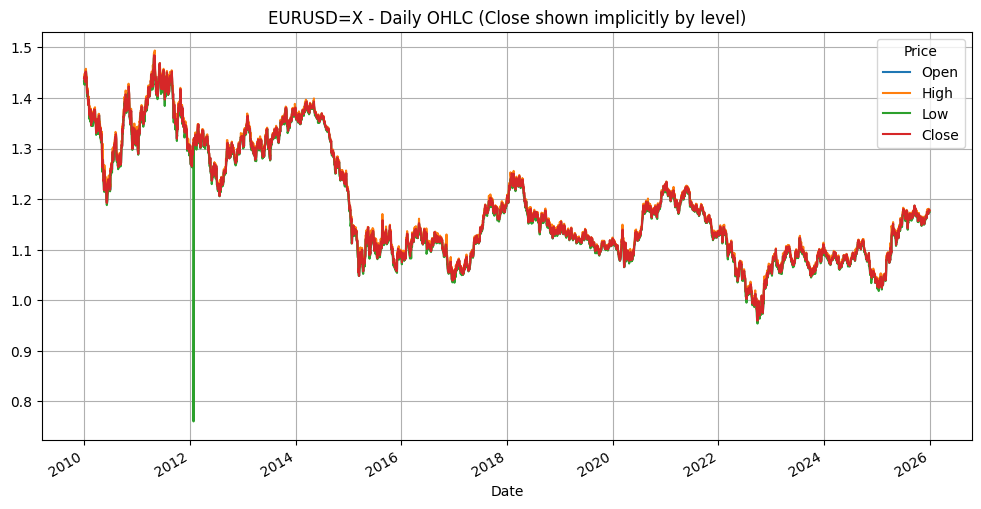

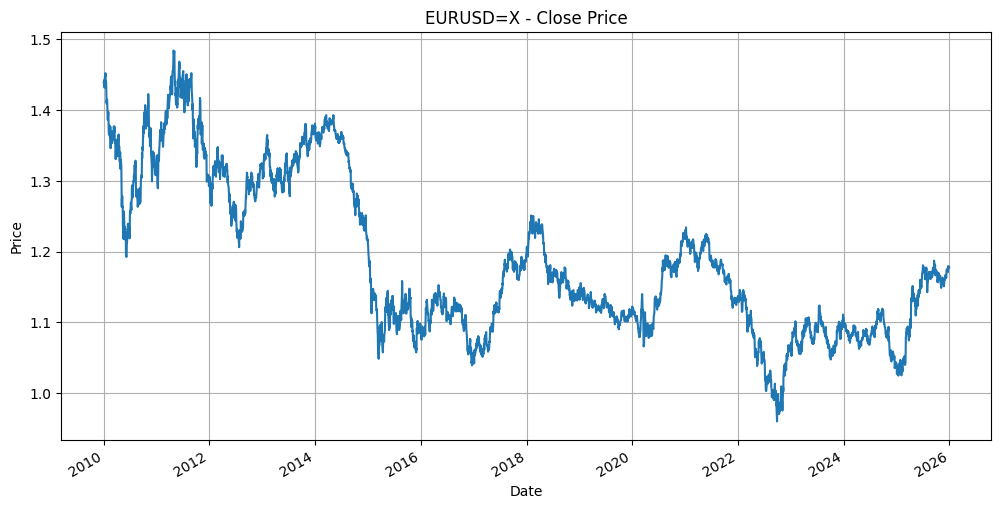

In [6]:
df[["Open", "High", "Low", "Close"]].plot(title=f"{ticker} - Daily OHLC (Close shown implicitly by level)")
plt.grid(True)
plt.show()

df["Close"].plot(title=f"{ticker} - Close Price")
plt.ylabel("Price")
plt.grid(True)
plt.show()

## 3. Signal construction

### Methodology

The signal-generation logic combines:

- **confirmed support levels**
- **confirmed resistance levels**
- **candlestick reversal patterns**

To reduce look-ahead bias:

- support/resistance levels are only considered if they were confirmed **before** the current bar,
- the trading signal is generated on the current bar,
- the order is executed by the backtesting engine on the **next bar**.

### Signal convention

- `+1` = bullish signal → long entry
- `-1` = bearish signal → short entry
- `0` = no signal

In [7]:
def is_support(data: pd.DataFrame, idx: int, n1: int, n2: int) -> bool:
    """
    A support is defined as a local minimum:
    - lows decreasing (or not increasing) into the pivot
    - lows increasing (or not decreasing) after the pivot
    """
    if idx - n1 < 0 or idx + n2 >= len(data):
        return False

    lows = data["Low"].values

    for i in range(idx - n1 + 1, idx + 1):
        if lows[i] > lows[i - 1]:
            return False

    for i in range(idx + 1, idx + n2 + 1):
        if lows[i] < lows[i - 1]:
            return False

    return True


def is_resistance(data: pd.DataFrame, idx: int, n1: int, n2: int) -> bool:
    """
    A resistance is defined as a local maximum:
    - highs increasing (or not decreasing) into the pivot
    - highs decreasing (or not increasing) after the pivot
    """
    if idx - n1 < 0 or idx + n2 >= len(data):
        return False

    highs = data["High"].values

    for i in range(idx - n1 + 1, idx + 1):
        if highs[i] < highs[i - 1]:
            return False

    for i in range(idx + 1, idx + n2 + 1):
        if highs[i] > highs[i - 1]:
            return False

    return True


def bullish_engulfing(data: pd.DataFrame, idx: int, min_body: float = 0.0005) -> bool:
    """
    Bullish engulfing:
    - previous candle bearish
    - current candle bullish
    - current real body engulfs previous real body
    """
    if idx < 1:
        return False

    prev_open = data["Open"].iloc[idx - 1]
    prev_close = data["Close"].iloc[idx - 1]
    curr_open = data["Open"].iloc[idx]
    curr_close = data["Close"].iloc[idx]

    prev_body = abs(prev_close - prev_open)
    curr_body = abs(curr_close - curr_open)

    if prev_body < min_body or curr_body < min_body:
        return False

    prev_bearish = prev_close < prev_open
    curr_bullish = curr_close > curr_open

    body_engulf = (curr_open <= prev_close) and (curr_close >= prev_open)

    return prev_bearish and curr_bullish and body_engulf


def bearish_engulfing(data: pd.DataFrame, idx: int, min_body: float = 0.0005) -> bool:
    """
    Bearish engulfing:
    - previous candle bullish
    - current candle bearish
    - current real body engulfs previous real body
    """
    if idx < 1:
        return False

    prev_open = data["Open"].iloc[idx - 1]
    prev_close = data["Close"].iloc[idx - 1]
    curr_open = data["Open"].iloc[idx]
    curr_close = data["Close"].iloc[idx]

    prev_body = abs(prev_close - prev_open)
    curr_body = abs(curr_close - curr_open)

    if prev_body < min_body or curr_body < min_body:
        return False

    prev_bullish = prev_close > prev_open
    curr_bearish = curr_close < curr_open

    body_engulf = (curr_open >= prev_close) and (curr_close <= prev_open)

    return prev_bullish and curr_bearish and body_engulf


def bullish_pinbar(data: pd.DataFrame, idx: int, body_threshold: float = 0.35, wick_ratio: float = 2.0) -> bool:
    """
    Bullish pin bar / hammer-like candle:
    - relatively small body
    - long lower wick
    - upper wick not dominant
    """
    o = data["Open"].iloc[idx]
    h = data["High"].iloc[idx]
    l = data["Low"].iloc[idx]
    c = data["Close"].iloc[idx]

    candle_range = h - l
    if candle_range <= 0:
        return False

    body = abs(c - o)
    upper_wick = h - max(o, c)
    lower_wick = min(o, c) - l

    small_body = body / candle_range <= body_threshold
    long_lower_wick = lower_wick >= wick_ratio * max(body, 1e-8)
    controlled_upper_wick = upper_wick <= lower_wick

    return small_body and long_lower_wick and controlled_upper_wick


def bearish_pinbar(data: pd.DataFrame, idx: int, body_threshold: float = 0.35, wick_ratio: float = 2.0) -> bool:
    """
    Bearish pin bar / shooting-star-like candle:
    - relatively small body
    - long upper wick
    - lower wick not dominant
    """
    o = data["Open"].iloc[idx]
    h = data["High"].iloc[idx]
    l = data["Low"].iloc[idx]
    c = data["Close"].iloc[idx]

    candle_range = h - l
    if candle_range <= 0:
        return False

    body = abs(c - o)
    upper_wick = h - max(o, c)
    lower_wick = min(o, c) - l

    small_body = body / candle_range <= body_threshold
    long_upper_wick = upper_wick >= wick_ratio * max(body, 1e-8)
    controlled_lower_wick = lower_wick <= upper_wick

    return small_body and long_upper_wick and controlled_lower_wick


def is_close_to_level(price: float, levels: list[float], tolerance: float) -> bool:
    """
    Returns True if price is within a tolerance band of at least one level.
    """
    if len(levels) == 0:
        return False
    return np.min(np.abs(np.array(levels) - price)) <= tolerance

In [8]:
# Strategy parameters for signal generation
n1 = 2                     # candles before pivot
n2 = 2                     # candles after pivot confirmation
lookback = 40              # rolling window for collecting past confirmed levels
price_tolerance = 0.0030   # proximity threshold to support/resistance (~0.30 cents on EURUSD)
min_body = 0.0005          # minimum body size for engulfing pattern

signals = np.zeros(len(df), dtype=int)
support_levels_col = [[] for _ in range(len(df))]
resistance_levels_col = [[] for _ in range(len(df))]

for idx in range(len(df)):
    # Only use pivot levels that are fully confirmed before the current bar
    # A pivot at j is confirmed only after j + n2 bars are completed.
    candidate_start = max(n1, idx - lookback)
    candidate_end = idx - n2  # last pivot index that can already be confirmed by idx

    supports = []
    resistances = []

    if candidate_end > candidate_start:
        for j in range(candidate_start, candidate_end):
            if is_support(df, j, n1, n2):
                supports.append(df["Low"].iloc[j])
            if is_resistance(df, j, n1, n2):
                resistances.append(df["High"].iloc[j])

    support_levels_col[idx] = supports.copy()
    resistance_levels_col[idx] = resistances.copy()

    close_price = df["Close"].iloc[idx]

    bullish_pattern = bullish_engulfing(df, idx, min_body=min_body) or bullish_pinbar(df, idx)
    bearish_pattern = bearish_engulfing(df, idx, min_body=min_body) or bearish_pinbar(df, idx)

    near_support = is_close_to_level(close_price, supports, price_tolerance)
    near_resistance = is_close_to_level(close_price, resistances, price_tolerance)

    if bullish_pattern and near_support:
        signals[idx] = 1
    elif bearish_pattern and near_resistance:
        signals[idx] = -1
    else:
        signals[idx] = 0

df["Signal"] = signals
df["Support_Levels"] = support_levels_col
df["Resistance_Levels"] = resistance_levels_col

df[["Open", "High", "Low", "Close", "Signal"]].tail(10)

Price,Open,High,Low,Close,Signal
Date,,,,,
2025-12-16,1.175503,1.180470,1.174605,1.175461,0
2025-12-17,1.174964,1.175793,1.170453,1.174950,0
2025-12-18,1.174219,1.175890,1.171344,1.174233,0
2025-12-19,1.172539,1.173750,1.170412,1.172567,0
2025-12-22,1.171084,1.177024,1.171084,1.170809,0
2025-12-23,1.176443,1.180359,1.176429,1.176595,0
2025-12-24,1.179565,1.180916,1.177426,1.179551,0
2025-12-26,1.178384,1.179941,1.176304,1.178536,0
2025-12-29,1.177496,1.178856,1.175406,1.177274,0


In [9]:
signal_counts = df["Signal"].value_counts().sort_index()
signal_counts

Signal
-1     388
 0    3326
 1     450
Name: count, dtype: int64

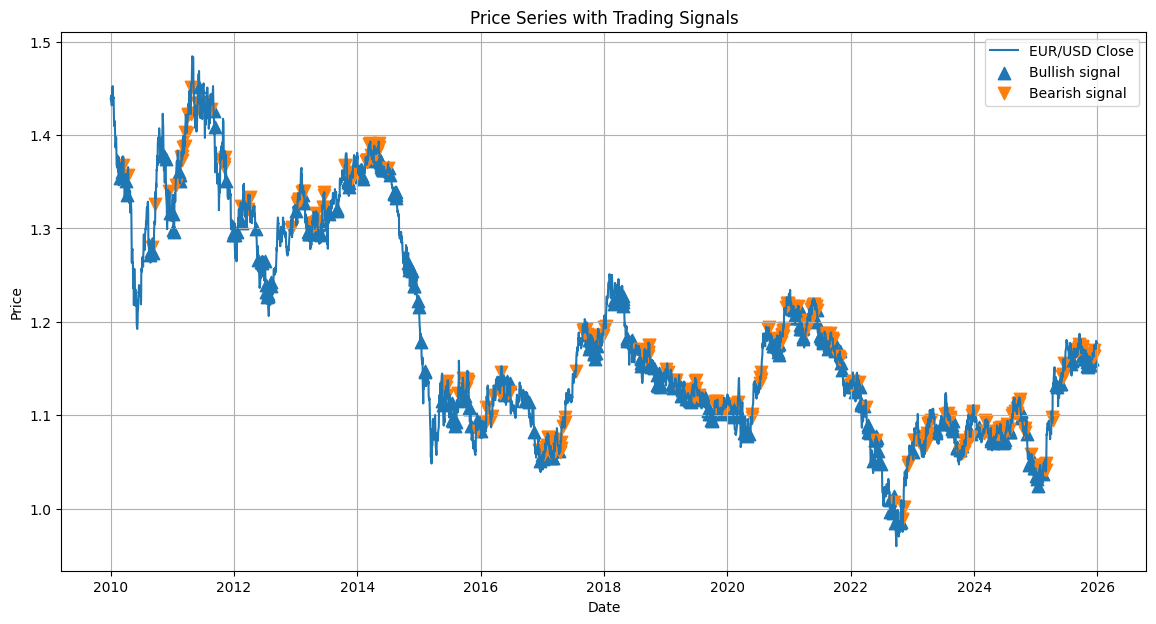

In [13]:
# Quick visual check of where signals appear on price
plt.figure(figsize=(14, 7))
plt.plot(df.index, df["Close"], label="EUR/USD Close")

buy_idx = df.index[df["Signal"] == 1]
sell_idx = df.index[df["Signal"] == -1]

plt.scatter(buy_idx, df.loc[buy_idx, "Close"], marker="^", s=80, label="Bullish signal")
plt.scatter(sell_idx, df.loc[sell_idx, "Close"], marker="v", s=80, label="Bearish signal")

plt.title("Price Series with Trading Signals")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()

## 4. Backtesting setup

The strategy rules are intentionally simple:

- enter **long** on a bullish signal,
- enter **short** on a bearish signal,
- use fixed **stop loss** and **take profit** distances,
- keep at most one position open at a time.

Since `backtesting.py` executes orders after the signal bar, the implementation is aligned with a realistic bar-by-bar simulation.

In [14]:
def SIGNAL():
    return df["Signal"].values

In [15]:
class SupportResistanceCandlesStrategy(Strategy):
    stop_loss_pct = 0.006   # 0.6%
    take_profit_pct = 0.010 # 1.0%
    position_size = 0.95    # invest 95% of available capital

    def init(self):
        self.signal = self.I(SIGNAL)

    def next(self):
        current_signal = self.signal[-1]
        current_close = self.data.Close[-1]

        # Only one position at a time
        if self.position:
            return

        # Long entry
        if current_signal == 1:
            sl = current_close * (1 - self.stop_loss_pct)
            tp = current_close * (1 + self.take_profit_pct)
            self.buy(size=self.position_size, sl=sl, tp=tp)

        # Short entry
        elif current_signal == -1:
            sl = current_close * (1 + self.stop_loss_pct)
            tp = current_close * (1 - self.take_profit_pct)
            self.sell(size=self.position_size, sl=sl, tp=tp)

In [16]:
bt = Backtest(
    df[["Open", "High", "Low", "Close", "Volume", "Signal"]].copy(),
    SupportResistanceCandlesStrategy,
    cash=10_000,
    commission=0.0002,      # 2 bps per trade side
    trade_on_close=False,
    exclusive_orders=True
)

stats = bt.run()
stats

Start                     2010-01-01 00:00:00
End                       2025-12-30 00:00:00
Duration                   5842 days 00:00:00
Exposure Time [%]                    33.66955
Equity Final [$]                    8659.1265
Equity Peak [$]                   10420.79028
Commissions [$]                    1772.00713
Return [%]                          -13.40873
Buy & Hold Return [%]               -18.18674
Return (Ann.) [%]                    -0.86751
Volatility (Ann.) [%]                 3.18283
CAGR [%]                             -0.61911
Sharpe Ratio                         -0.27256
Sortino Ratio                        -0.38523
Calmar Ratio                         -0.04225
Alpha [%]                           -13.29088
Beta                                  0.00648
Max. Drawdown [%]                   -20.53051
Avg. Drawdown [%]                    -5.85824
Max. Drawdown Duration     5423 days 00:00:00
Avg. Drawdown Duration     1408 days 00:00:00
# Trades                          

## 5. Performance summary

In [18]:
summary_keys = [
    "Start",
    "End",
    "Duration",
    "Exposure Time [%]",
    "Equity Final [$]",
    "Equity Peak [$]",
    "Return [%]",
    "Buy & Hold Return [%]",
    "Return (Ann.) [%]",
    "Volatility (Ann.) [%]",
    "Sharpe Ratio",
    "Sortino Ratio",
    "Calmar Ratio",
    "Max. Drawdown [%]",
    "Avg. Drawdown [%]",
    "# Trades",
    "Win Rate [%]",
    "Best Trade [%]",
    "Worst Trade [%]",
    "Avg. Trade [%]",
    "Max. Trade Duration",
    "Avg. Trade Duration",
    "Profit Factor",
    "Expectancy [%]",
    "SQN",
]

available_summary = {k: stats[k] for k in summary_keys if k in stats.index}
summary_df = pd.DataFrame.from_dict(available_summary, orient="index", columns=["Value"])
summary_df

,Value
Start,2010-01-01 00:00:00
End,2025-12-30 00:00:00
Duration,5842 days 00:00:00
Exposure Time [%],33.669549
Equity Final [$],8659.126503
Equity Peak [$],10420.79028
Return [%],-13.408735
Buy & Hold Return [%],-18.186735
Return (Ann.) [%],-0.867511
Volatility (Ann.) [%],3.182827


In [19]:
equity_curve = stats["_equity_curve"].copy()
trades = stats["_trades"].copy()

equity_curve.head(), trades.head()

(             Equity  DrawdownPct DrawdownDuration
 Date                                             
 2010-01-01  10000.0          0.0              NaT
 2010-01-04  10000.0          0.0              NaT
 2010-01-05  10000.0          0.0              NaT
 2010-01-06  10000.0          0.0              NaT
 2010-01-07  10000.0          0.0              NaT,
    Size  EntryBar  ExitBar  EntryPrice  ExitPrice        SL        TP  \
 0  7016        40       40    1.353748   1.367137  1.345480  1.367137   
 1  7042        48       50    1.360933   1.374299  1.352528  1.374299   
 2 -7071        52       52    1.367372   1.375952  1.375952  1.354068   
 3  7112        64       67    1.350840   1.342699  1.342699  1.364312   
 4  7147        70       70    1.336095   1.349474  1.328096  1.349474   
 
          PnL  Commission  ReturnPct  EntryTime   ExitTime Duration   Tag  \
 0  90.121977    3.817946   0.009489 2010-02-26 2010-02-26   0 days  None   
 1  90.272755    3.852301   0.009419 2010-

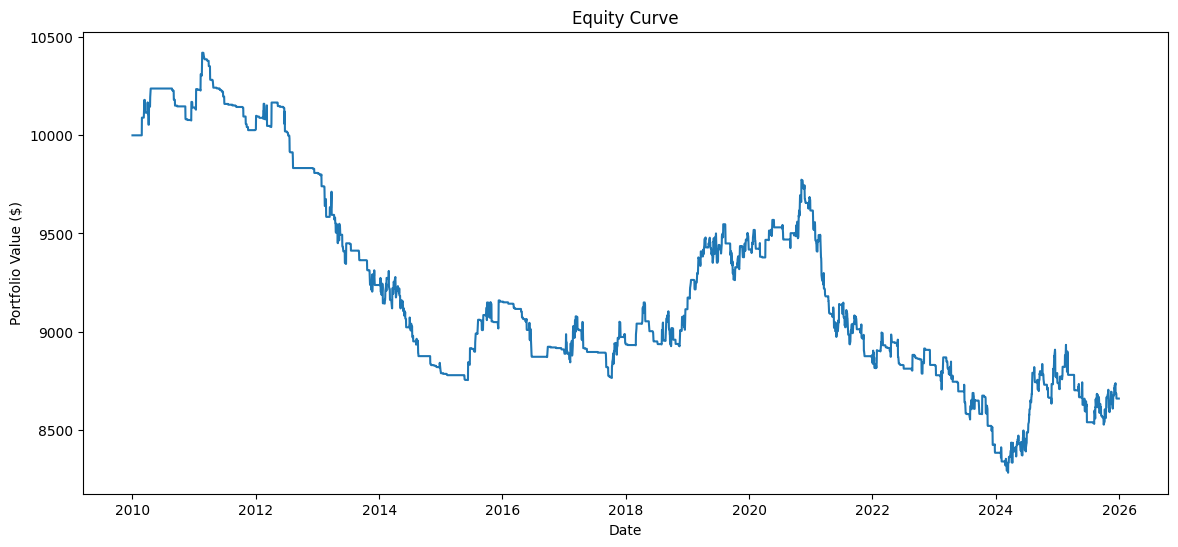

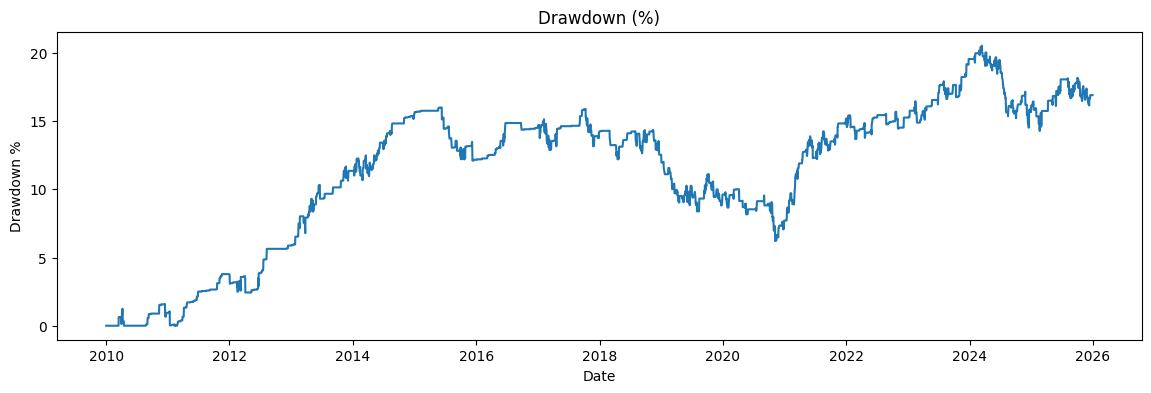

In [20]:
# Equity curve
plt.figure(figsize=(14, 6))
plt.plot(equity_curve.index, equity_curve["Equity"])
plt.title("Equity Curve")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.show()

# Drawdown
if "DrawdownPct" in equity_curve.columns:
    plt.figure(figsize=(14, 4))
    plt.plot(equity_curve.index, equity_curve["DrawdownPct"] * 100)
    plt.title("Drawdown (%)")
    plt.xlabel("Date")
    plt.ylabel("Drawdown %")
    plt.show()

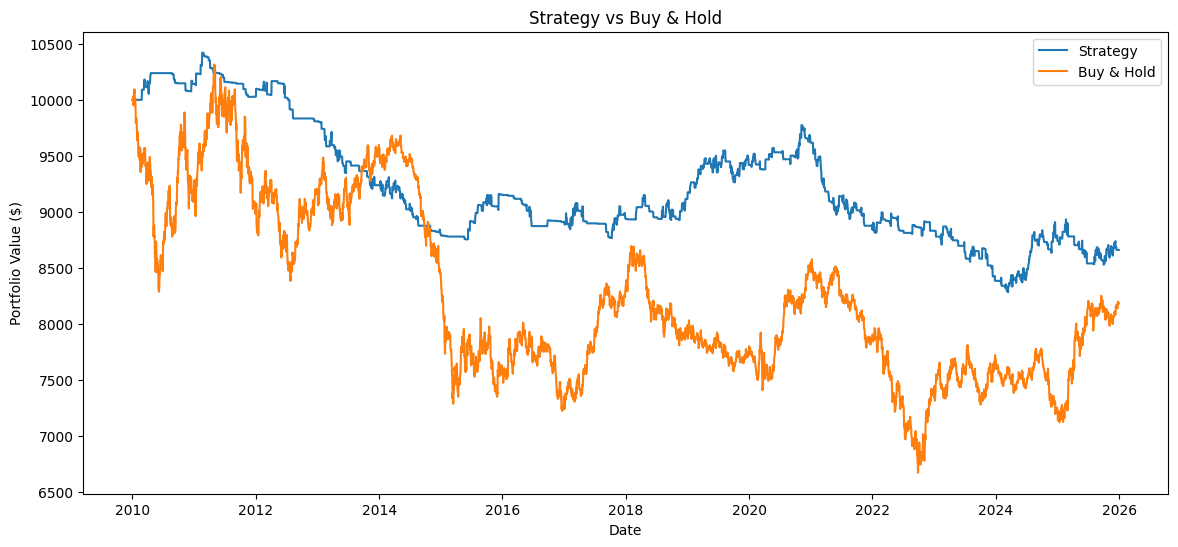

In [21]:
# Benchmark comparison: strategy equity vs buy-and-hold normalized to 10,000
initial_cash = 10_000

buy_hold_curve = initial_cash * (df["Close"] / df["Close"].iloc[0])

plt.figure(figsize=(14, 6))
plt.plot(equity_curve.index, equity_curve["Equity"], label="Strategy")
plt.plot(df.index, buy_hold_curve, label="Buy & Hold")
plt.title("Strategy vs Buy & Hold")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.legend()
plt.show()

In [22]:
# Trade diagnostics
if not trades.empty:
    display_cols = [col for col in [
        "Size", "EntryBar", "ExitBar", "EntryPrice", "ExitPrice",
        "SL", "TP", "PnL", "ReturnPct", "EntryTime", "ExitTime", "Duration"
    ] if col in trades.columns]

    trades[display_cols].head(15)
else:
    print("No trades were generated.")

## 6. Interpretation

This project illustrates a complete workflow for building and evaluating a rule-based FX strategy.

### Strengths of the approach

- transparent and interpretable rules,
- no black-box model,
- explicit risk management through stop loss and take profit,
- careful signal construction designed to reduce look-ahead bias.

### Main limitations

- support and resistance detection is rule-based and somewhat subjective,
- candlestick patterns alone may not provide stable predictive power,
- results can be sensitive to tolerance thresholds and stop-loss / take-profit settings,
- transaction costs, slippage, and execution effects are simplified,
- the strategy is tested on a single instrument and timeframe.

### Possible extensions

- parameter sensitivity analysis,
- walk-forward validation,
- multi-asset testing,
- volatility filters,
- trend filters,
- position sizing based on risk rather than fixed capital fraction.

In [23]:
# Optional: compact final report dictionary
final_report = {
    "Ticker": ticker,
    "Start date": df.index.min().date(),
    "End date": df.index.max().date(),
    "Observations": len(df),
    "Bullish signals": int((df["Signal"] == 1).sum()),
    "Bearish signals": int((df["Signal"] == -1).sum()),
    "Total return (%)": float(stats["Return [%]"]) if "Return [%]" in stats.index else np.nan,
    "Buy & Hold return (%)": float(stats["Buy & Hold Return [%]"]) if "Buy & Hold Return [%]" in stats.index else np.nan,
    "Annualized return (%)": float(stats["Return (Ann.) [%]"]) if "Return (Ann.) [%]" in stats.index else np.nan,
    "Annualized volatility (%)": float(stats["Volatility (Ann.) [%]"]) if "Volatility (Ann.) [%]" in stats.index else np.nan,
    "Sharpe ratio": float(stats["Sharpe Ratio"]) if "Sharpe Ratio" in stats.index else np.nan,
    "Max drawdown (%)": float(stats["Max. Drawdown [%]"]) if "Max. Drawdown [%]" in stats.index else np.nan,
    "Number of trades": int(stats["# Trades"]) if "# Trades" in stats.index else np.nan,
    "Win rate (%)": float(stats["Win Rate [%]"]) if "Win Rate [%]" in stats.index else np.nan,
}

pd.DataFrame(final_report.items(), columns=["Metric", "Value"])

,Metric,Value
0,Ticker,EURUSD=X
1,Start date,2010-01-01
2,End date,2025-12-30
3,Observations,4164
4,Bullish signals,450
5,Bearish signals,388
6,Total return (%),-13.408735
7,Buy & Hold return (%),-18.186735
8,Annualized return (%),-0.867511
9,Annualized volatility (%),3.182827


## Conclusion

- The strategy **underperforms in absolute terms**, but **outperforms buy-and-hold** in a declining market environment.
- A large number of trades leads to **significant transaction costs**, which materially impact performance.
- The combination of support/resistance levels and candlestick patterns appears to generate **no clear statistical edge** in its current form.

This backtest highlights the difficulty of translating discretionary trading concepts into systematic strategies.

While the current implementation does not produce positive returns, it provides a solid quantitative framework for:

- signal construction,
- rule-based trading,
- and performance evaluation.

Future improvements should focus on **signal filtering, risk-reward optimization, and robustness testing**.